# dscdemand: Does buying one good create demand for another?

A household that buys more hand sanitizer may later need more hand lotion,
because heavy sanitizer use dries the skin. But for a **storable** good, a
purchase is not a use: a household that just bought lotion is restocking and
will buy less for a while. Purchase histories alone cannot tell these two
forces apart.

`dscdemand` separates them with a **dynamic discrete choice model** of
household-week purchases. This notebook walks through one complete analysis
and answers three questions:

1. **Spillover**: do recent purchases of the upstream good (sanitizer) raise
   demand for the downstream good (lotion)?
2. **Stockpiling vs. heterogeneity**: does holding inventory lower demand,
   and does that effect survive once households are allowed to differ?
3. **Dynamics**: after one extra upstream purchase, how does demand evolve
   week by week, and how much of the extra demand is later offset?

The data are **synthetic**, generated with known parameters, so every
estimate can be checked against the truth. The research application of this
package uses Nielsen Consumer Panel data, which cannot be shared.

## 0. Before you run

This notebook needs the `dscdemand` conda environment. From the repository
root, run once:

```
conda env create -f environment.yml
conda activate dscdemand
pip install -e .
python -m ipykernel install --user --name dscdemand --display-name "Python (dscdemand)" --env OPENBLAS_NUM_THREADS 1
```

(`make init` does the same.) Then select the kernel **Python (dscdemand)**.
In VS Code, click *Select Kernel* at the top right, then *Jupyter Kernel...*
and **Python (dscdemand)** (or *Python Environments...* and the `dscdemand`
conda environment). In JupyterLab, use *Kernel > Change Kernel*. Then run
all cells; the whole notebook takes about one minute. If
the first cell raises `ModuleNotFoundError: dscdemand`, the wrong kernel is
selected.

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dscdemand import StorableComplementaryModel, load_example, multipliers

plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)

## 1. The data: a household-week panel

Each row is one household in one week:

| Column | Meaning |
|---|---|
| `upstream` | units of the upstream good bought (sanitizer) |
| `purchase` | 1 if the household bought the downstream good (lotion) |
| `volume` | units of the downstream good bought |
| `price` | downstream price that week |
| `event` | 1 during a three-week surprise surge in upstream buying (weeks 40-42), like the COVID-19 sanitizer panic |

In [14]:
dataset = load_example()
df = dataset.data
n_weeks = df["week"].nunique()
print(f"{dataset.n_households} households x {n_weeks} weeks = {dataset.n_rows} rows")
df.head()

300 households x 60 weeks = 18000 rows


,household,week,upstream,purchase,volume,price,event
0,0,0,0.0,0,0.0,4.23,0
1,0,1,0.0,1,1.0,3.56,0
2,0,2,3.0,0,0.0,3.60,0
3,0,3,0.0,0,0.0,4.51,0
4,0,4,1.0,0,0.0,3.72,0


The raw pattern that motivates the model: when upstream buying surges,
downstream buying rises too, and falls back quickly once the surge ends.

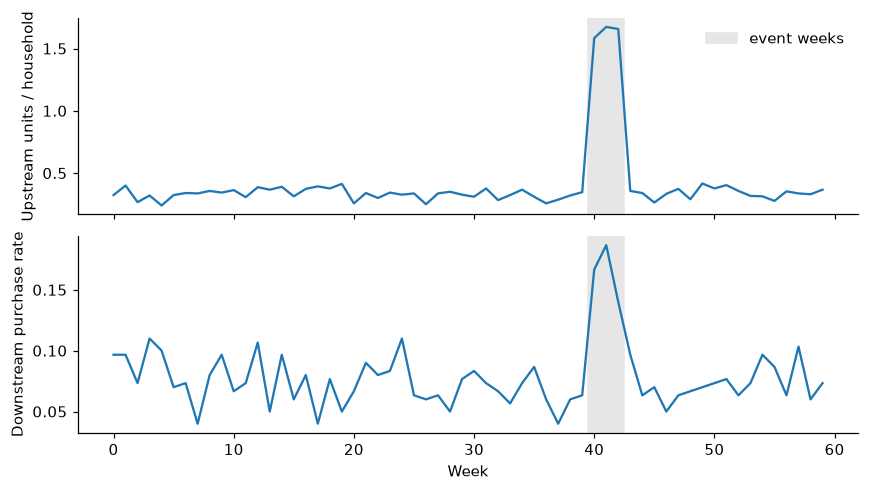

In [15]:
weekly = df.groupby("week")[["upstream", "purchase"]].mean()

fig, axes = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True)
for ax, col, label in zip(
    axes,
    ["upstream", "purchase"],
    ["Upstream units / household", "Downstream purchase rate"],
    strict=True,
):
    ax.axvspan(39.5, 42.5, color="0.9", label="event weeks")
    ax.plot(weekly.index, weekly[col], color="C0")
    ax.set_ylabel(label)
axes[0].legend(frameon=False)
axes[1].set_xlabel("Week")
fig.tight_layout()

A correlation like this is not yet evidence of a spillover: the surge
could also coincide with other changes, and households differ in how often
they buy anything. The model makes the mechanism explicit.

## 2. The model

Each week a household decides whether to buy the downstream good. Two stocks
summarize its history:

- **exposure** $K$, built by recent upstream purchases $S$: $K' = \eta K + S$
- **inventory** $\xi$, built by its own downstream purchases $Q$: $\xi' = \rho\,\xi + Q$

The flow utility of buying (not buying is normalized to 0) is

$$
u_1 = a + f(K;\gamma_1,\gamma_2) + \lambda\,\xi + \alpha\,\text{price} + b\,\text{event},
$$

where $f$ is piecewise linear in exposure (slope $\gamma_1$ up to a kink,
$\gamma_2$ after). Households are forward-looking: they compare the value of
buying now with the value of waiting, given how their stocks will evolve.
The purchase probability comes from solving this dynamic program (a Bellman
equation), and the parameters are estimated by nested fixed point maximum
likelihood (Rust, 1987).

The retention rates $\eta, \rho$ and the discount factor $\beta = 0.95$ are
fixed. `event` is declared **unanticipated**: households do not expect it
when planning ahead.

## 3. Estimate the model

In [16]:
model = StorableComplementaryModel(eta=0.6, rho=0.8, unanticipated=("event",))
model.fit(dataset)
print(f"log-likelihood = {model.loglik_:.1f}, converged = {model.converged_}")

log-likelihood = -4641.3, converged = True


In [17]:
truth = {
    "a": 1.0,
    "gamma1": 0.8,
    "gamma2": 0.2,
    "lam": -2.5,
    "alpha": -0.4,
    "event": 1.0,
}
meaning = {
    "a": "baseline utility of buying",
    "gamma1": "spillover: effect of exposure (below kink)",
    "gamma2": "spillover: effect of exposure (above kink)",
    "lam": "stockpiling: effect of inventory",
    "alpha": "price sensitivity",
    "event": "direct effect of the event",
}
pd.DataFrame(
    {
        "estimate": model.params_["type_0"],
        "true value": pd.Series(truth),
        "meaning": pd.Series(meaning),
    }
).round(3)

,estimate,true value,meaning
a,1.167,1.0,baseline utility of buying
gamma1,0.618,0.8,spillover: effect of exposure (below kink)
gamma2,0.214,0.2,spillover: effect of exposure (above kink)
lam,-2.015,-2.5,stockpiling: effect of inventory
alpha,-0.428,-0.4,price sensitivity
event,0.868,1.0,direct effect of the event


**Answer to question 1.** $\hat\gamma_1 > 0$: recent upstream purchases
raise the value of buying downstream, a cross-category spillover.
$\hat\lambda < 0$: households holding inventory buy less, the storability
effect. Signs and magnitudes are close to the truth. The intercept is a bit
high and $\lambda$ a bit attenuated because the state grid is built from
data (see the README's limitations); `tests/` checks exact recovery with the
true grid.

## 4. Does the model fit the data?

`predict_proba()` gives each household-week's predicted purchase
probability. Averaging by week and comparing with the observed purchase
rate is a standard in-sample fit check.

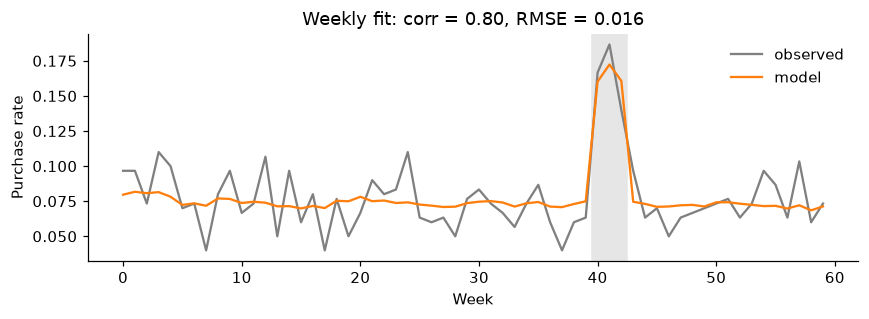

In [18]:
fit = model.predict_proba().groupby("week")[["purchase", "p_buy"]].mean()
corr = np.corrcoef(fit["purchase"], fit["p_buy"])[0, 1]
rmse = np.sqrt(((fit["purchase"] - fit["p_buy"]) ** 2).mean())

fig, ax = plt.subplots(figsize=(8, 3))
ax.axvspan(39.5, 42.5, color="0.9")
ax.plot(fit.index, fit["purchase"], color="0.5", label="observed")
ax.plot(fit.index, fit["p_buy"], color="C1", label="model")
ax.set(
    xlabel="Week",
    ylabel="Purchase rate",
    title=f"Weekly fit: corr = {corr:.2f}, RMSE = {rmse:.3f}",
)
ax.legend(frameon=False)
fig.tight_layout()

The model reproduces the jump during the event and the elevated weeks
after it. Week-to-week noise is sampling variation in a panel of 300
households.

## 5. What the model learned: the purchase policy

`policy()` returns the probability of buying at every combination of
exposure $K$ and inventory $\xi$ (at the average price, outside the event).
This is the household's decision rule implied by the estimates.

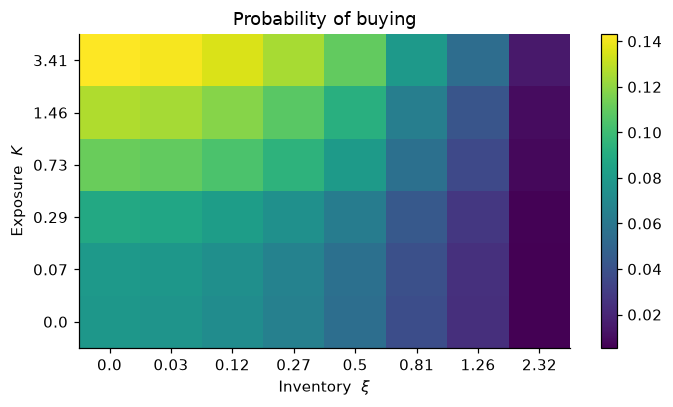

In [19]:
policy = model.policy()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
im = ax.imshow(policy.values, origin="lower", aspect="auto", cmap="viridis")
ax.set_xticks(range(policy.shape[1]), policy.columns)
ax.set_yticks(range(policy.shape[0]), policy.index)
ax.set(
    xlabel="Inventory  $\\xi$", ylabel="Exposure  $K$", title="Probability of buying"
)
fig.colorbar(im, ax=ax)
fig.tight_layout()

Moving **up** (more recent upstream purchases) raises the probability of
buying; moving **right** (more inventory on hand) lowers it. These two
gradients are the spillover and stockpiling channels that a raw correlation
mixes together.

## 6. Stockpiling or heterogeneity?

Some households simply buy more often than others. A heavy buyer also tends
to hold more inventory, so a model that ignores these differences can
mistake "who the household is" for "what the household holds". This is the
classic **state dependence vs. unobserved heterogeneity** problem.

To show it, we simulate a panel with two household types that differ only
in their baseline taste $a$, and fit it twice: once assuming all households
are alike, and once with two types estimated by EM (`n_types=2`).
The EM fit takes about 30 seconds.

In [20]:
two_types = [
    dict(
        a=1.5, gamma1=0.8, gamma2=0.2, lam=-0.5, alpha=-0.4, event=1.0
    ),  # frequent buyers
    dict(
        a=-1.0, gamma1=0.8, gamma2=0.2, lam=-0.5, alpha=-0.4, event=1.0
    ),  # rare buyers
]
mixed, mixed_truth = model.simulate(
    params=two_types, pi=[0.4, 0.6], n_households=300, n_weeks=60, seed=1
)

one_type = StorableComplementaryModel(eta=0.6, rho=0.8, unanticipated=("event",)).fit(
    mixed
)
em = StorableComplementaryModel(
    eta=0.6, rho=0.8, n_types=2, unanticipated=("event",)
).fit(mixed)

In [21]:
n_obs = mixed.n_rows
rows = []
for label, m in [("one type", one_type), ("two types (EM)", em)]:
    n_params = m.layout_.size + (m.layout_.n_types - 1)
    rows.append(
        {
            "model": label,
            "gamma1": m.params_.loc["gamma1"].iloc[0],
            "lam (by type)": ", ".join(f"{v:.2f}" for v in m.params_.loc["lam"]),
            "type shares": ", ".join(f"{p:.2f}" for p in m.pi_),
            "log-likelihood": m.loglik_,
            "BIC": -2 * m.loglik_ + n_params * np.log(n_obs),
        }
    )
rows.append(
    {
        "model": "truth",
        "gamma1": 0.8,
        "lam (by type)": "-0.50, -0.50",
        "type shares": "0.40, 0.60",
    }
)
pd.DataFrame(rows).set_index("model").round(2)

,gamma1,lam (by type),type shares,log-likelihood,BIC
model,,,,,
one type,0.43,-0.14,1.00,-6593.01,13244.81
two types (EM),0.63,"-0.65, -0.32","0.42, 0.58",-6309.01,12706.20
truth,0.80,"-0.50, -0.50","0.40, 0.60",NaN,NaN


In [22]:
share_correct = (em.responsibilities_.argmax(axis=1) == mixed_truth["types"]).mean()
print(f"EM assigns {share_correct:.0%} of households to their true type")

EM assigns 98% of households to their true type


**Answer to question 2.** Ignoring heterogeneity biases both channels
toward zero: the one-type model understates the spillover $\gamma_1$ and
the stockpiling effect $\lambda$, because frequent buyers both buy more and
hold more. Allowing two types recovers the type shares, classifies almost
every household correctly, and is strongly preferred by BIC. On real data
the same comparison is the test of whether an apparent own-history effect is
genuine or just persistent differences between households.

## 7. Dynamics: the response to an upstream shock

The main counterfactual: give every household one extra upstream purchase
this week and track the probability of buying over the next 26 weeks,
against a baseline without the shock. Households start from the observed
distribution of states. We compare a **typical** shock (2 units, the 75th
percentile of ordinary purchases) with an **event-sized** shock (4 units).

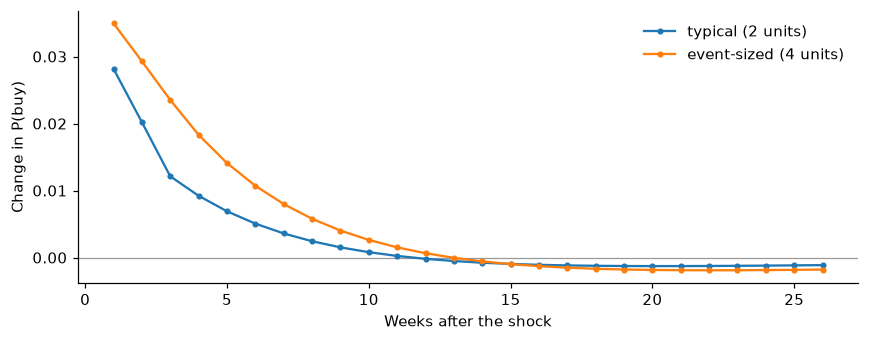

In [23]:
shocks = {"typical (2 units)": 2.0, "event-sized (4 units)": 4.0}
responses = {
    name: model.shock_response(shock=size, weeks=26) for name, size in shocks.items()
}

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.axhline(0, color="0.6", lw=0.8)
for name, r in responses.items():
    ax.plot(r["week"], r["response"], marker="o", ms=3, label=name)
ax.set(xlabel="Weeks after the shock", ylabel="Change in P(buy)")
ax.legend(frameon=False)
fig.tight_layout()

Demand jumps right after the shock and fades as exposure decays. Around
week 12 the response turns slightly **negative**: households that bought
early now hold more inventory and postpone their next purchase. The
negative tail is still present at week 26, so a longer horizon would show
a somewhat larger offset.

To summarize a path, `multipliers` adds up the weekly responses (extra
purchases per household):

- **gross**: extra purchases in the weeks with a positive response;
- **net**: extra purchases after subtracting the later reductions;
- **offset_ratio**: share of the gross gain that later weeks cancel
  ($1 - \text{net}/\text{gross}$).

In [24]:
summary = pd.DataFrame(
    {name: multipliers(r["response"]) for name, r in responses.items()}
).T
summary["net per unit of shock"] = summary["net"] / pd.Series(shocks)
summary.round(3)

,gross,net,offset_ratio,net per unit of shock
typical (2 units),0.090,0.075,0.173,0.037
event-sized (4 units),0.154,0.133,0.136,0.033


**Answer to question 3.** One extra upstream purchase creates lasting
extra downstream demand, but part of it (about 14-17% here) is pulled
forward from later weeks rather than new. Per unit of shock, the event-sized
shock has a smaller effect than the typical one because the spillover
flattens above the kink ($\gamma_2 < \gamma_1$), so results estimated at
panic scale do not transfer one-for-one to ordinary promotions. These
numbers come from synthetic data; with real data the size of the offset is
an empirical result.

## 8. Next steps

- **Your own data**: map your columns to the model's names with
  `PanelDataset`:

  ```python
  from dscdemand import PanelDataset

  dataset = PanelDataset(df, household="hh_id", week="week",
                         upstream="sanitizer_qty", purchase="bought_lotion",
                         volume="lotion_oz", price="lotion_price",
                         covariates=("event",))
  ```
- **Parameter recovery**: `model.simulate(params=[...])` generates panels with
  known parameters, as in section 6.
- **API reference**: `make docs`, then open `docs/index.html`.
- **Limitations**: see the README (fixed $\eta, \rho, \beta$; discretized
  states; no standard errors yet).